# 01-具身智能仿真概念


## 1. 本课主题与资料范围

这门课的课件总标题是 **《具身智能机器人仿真开发》**，以众擎 T800 人形机器人为对象，在 MuJoCo 中学习机器人仿真与运动控制。本篇对应第 01 节《具身智能仿真概念》，配套视频名为《01_T800具身智能开发介绍》。

本节先建立对开发过程的整体认识：具身智能解决什么问题，为什么选择 T800，以及机器人模型怎样在仿真环境中产生运动。后续各节再逐步实现模型加载、关节控制、策略驱动和物体交互。

**资料依据：**[用户提供的百度网盘课程资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。本篇依据 `ppt/01_具身智能仿真概念.pptx` 的 14 页课件预览整理，已逐页核对。第 2 页为问候页，第 14 页为品牌结束页，省略其中的非教学内容。图注页码均指原课件页码。

本篇使用课件作为主要来源，未转录配套视频，也未读取 `code.zip`。标为“工程补充”的段落用于解释当前概念，与课件原文区分。


## 2. 具身智能：通过身体与物理世界交互

课件先从常见的 AI 印象切入：在计算机中处理文字、代码或多媒体信息，例如聊天、写作和生成内容。随后把场景换成一个能拿起苹果的机器人，引出 **具身智能（Embodied AI）**。

这里的“具身”强调身体参与任务。机器人需要感知周围环境，控制自己的身体，再通过实际动作改变物体或自身的位置。任务结果体现在与物理世界的交互中。

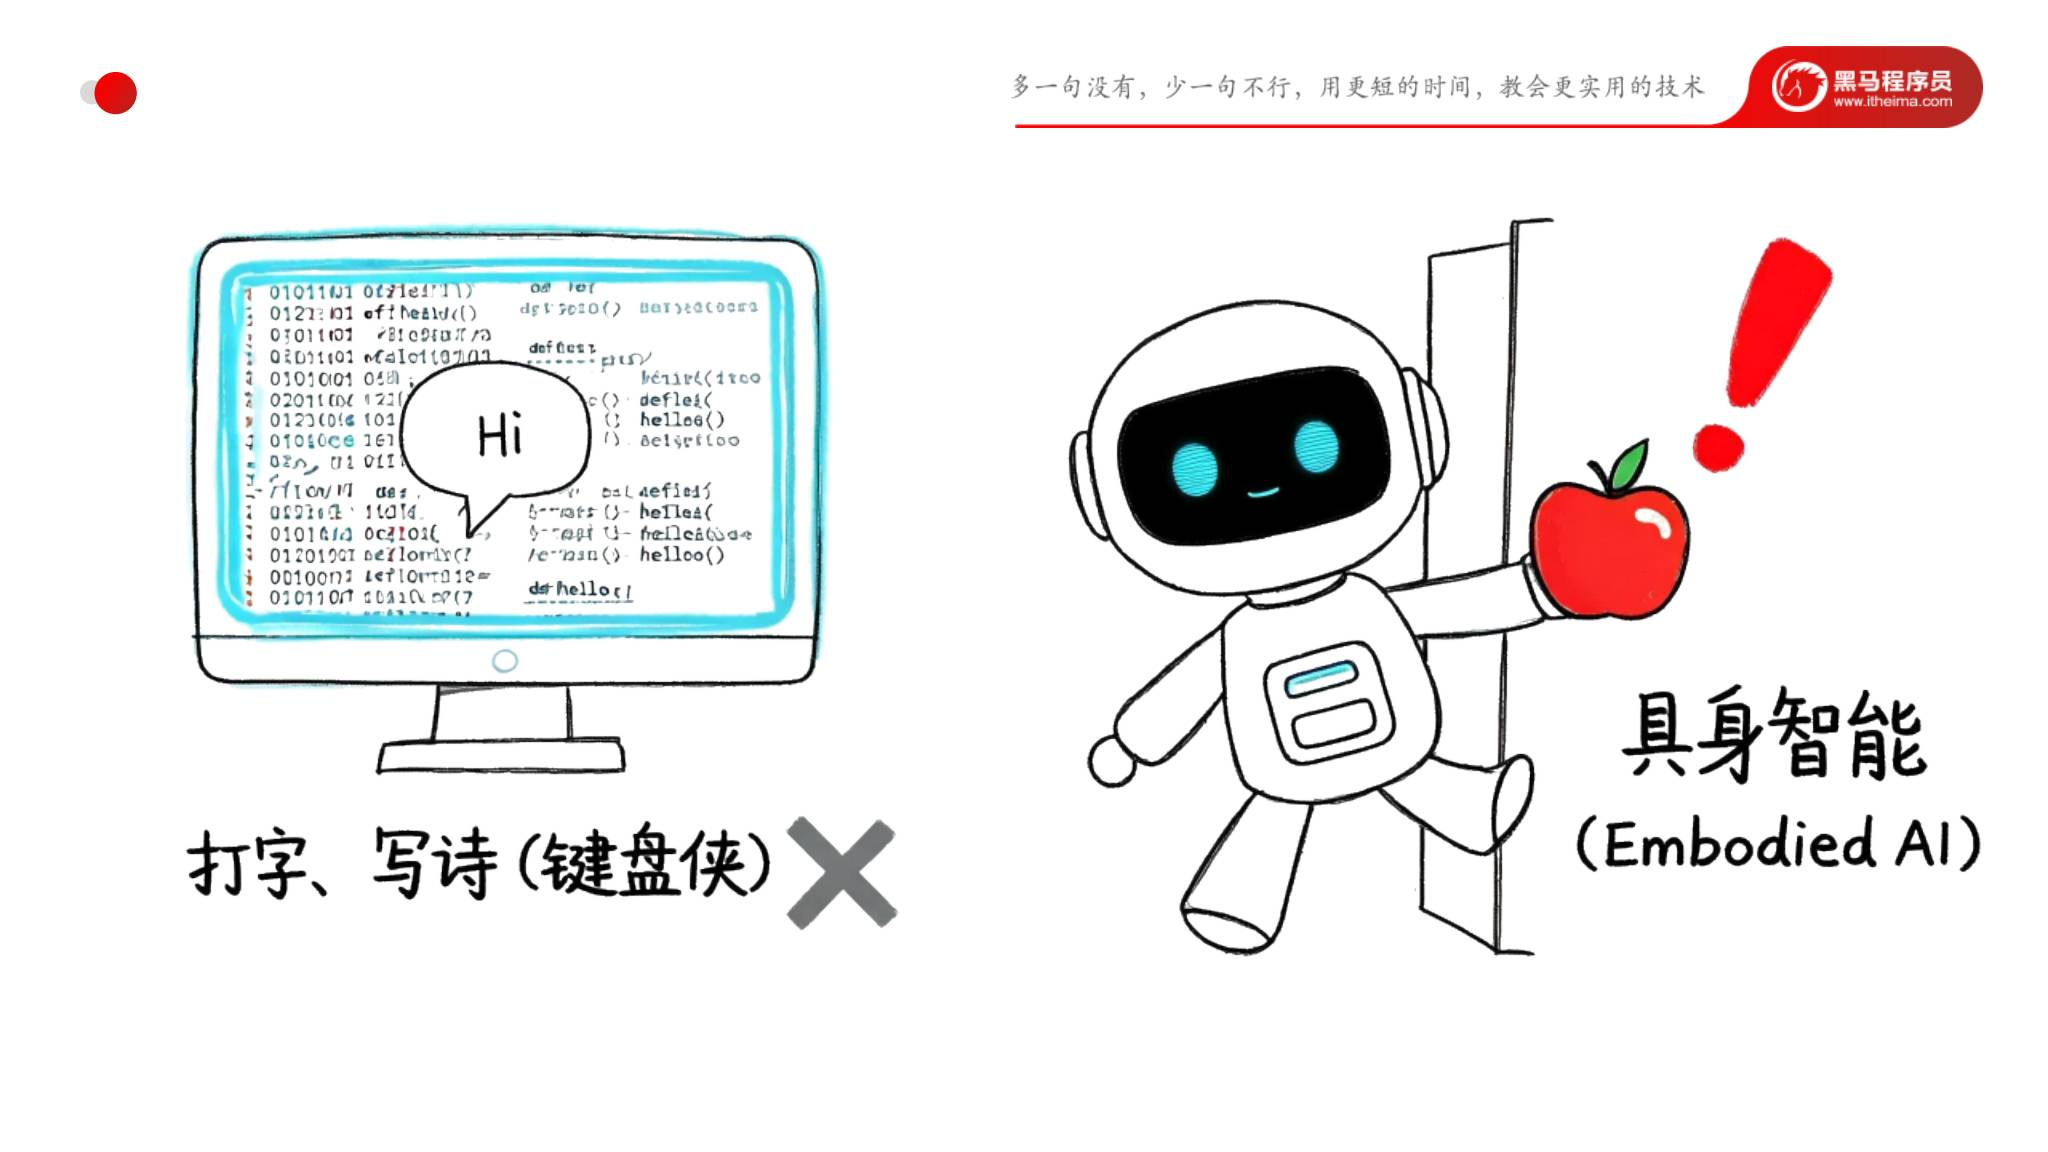

*原课件第 4 页：以文字生成与拿苹果的动作对照，引出具身智能。*

课件用一个搬提物品的机器人，把这个过程分成三部分：

| 环节 | 课件中的描述 | 在任务中要解决的问题 |
|---|---|---|
| 感知 | 视觉观察物理世界 | 周围有什么，目标物体在哪里 |
| 控制 | 四肢操控身体 | 怎样调整身体和关节，使手脚到达需要的位置 |
| 完成任务 | 与物理世界交互执行任务 | 通过抓取、提起或移动物体实现目标 |

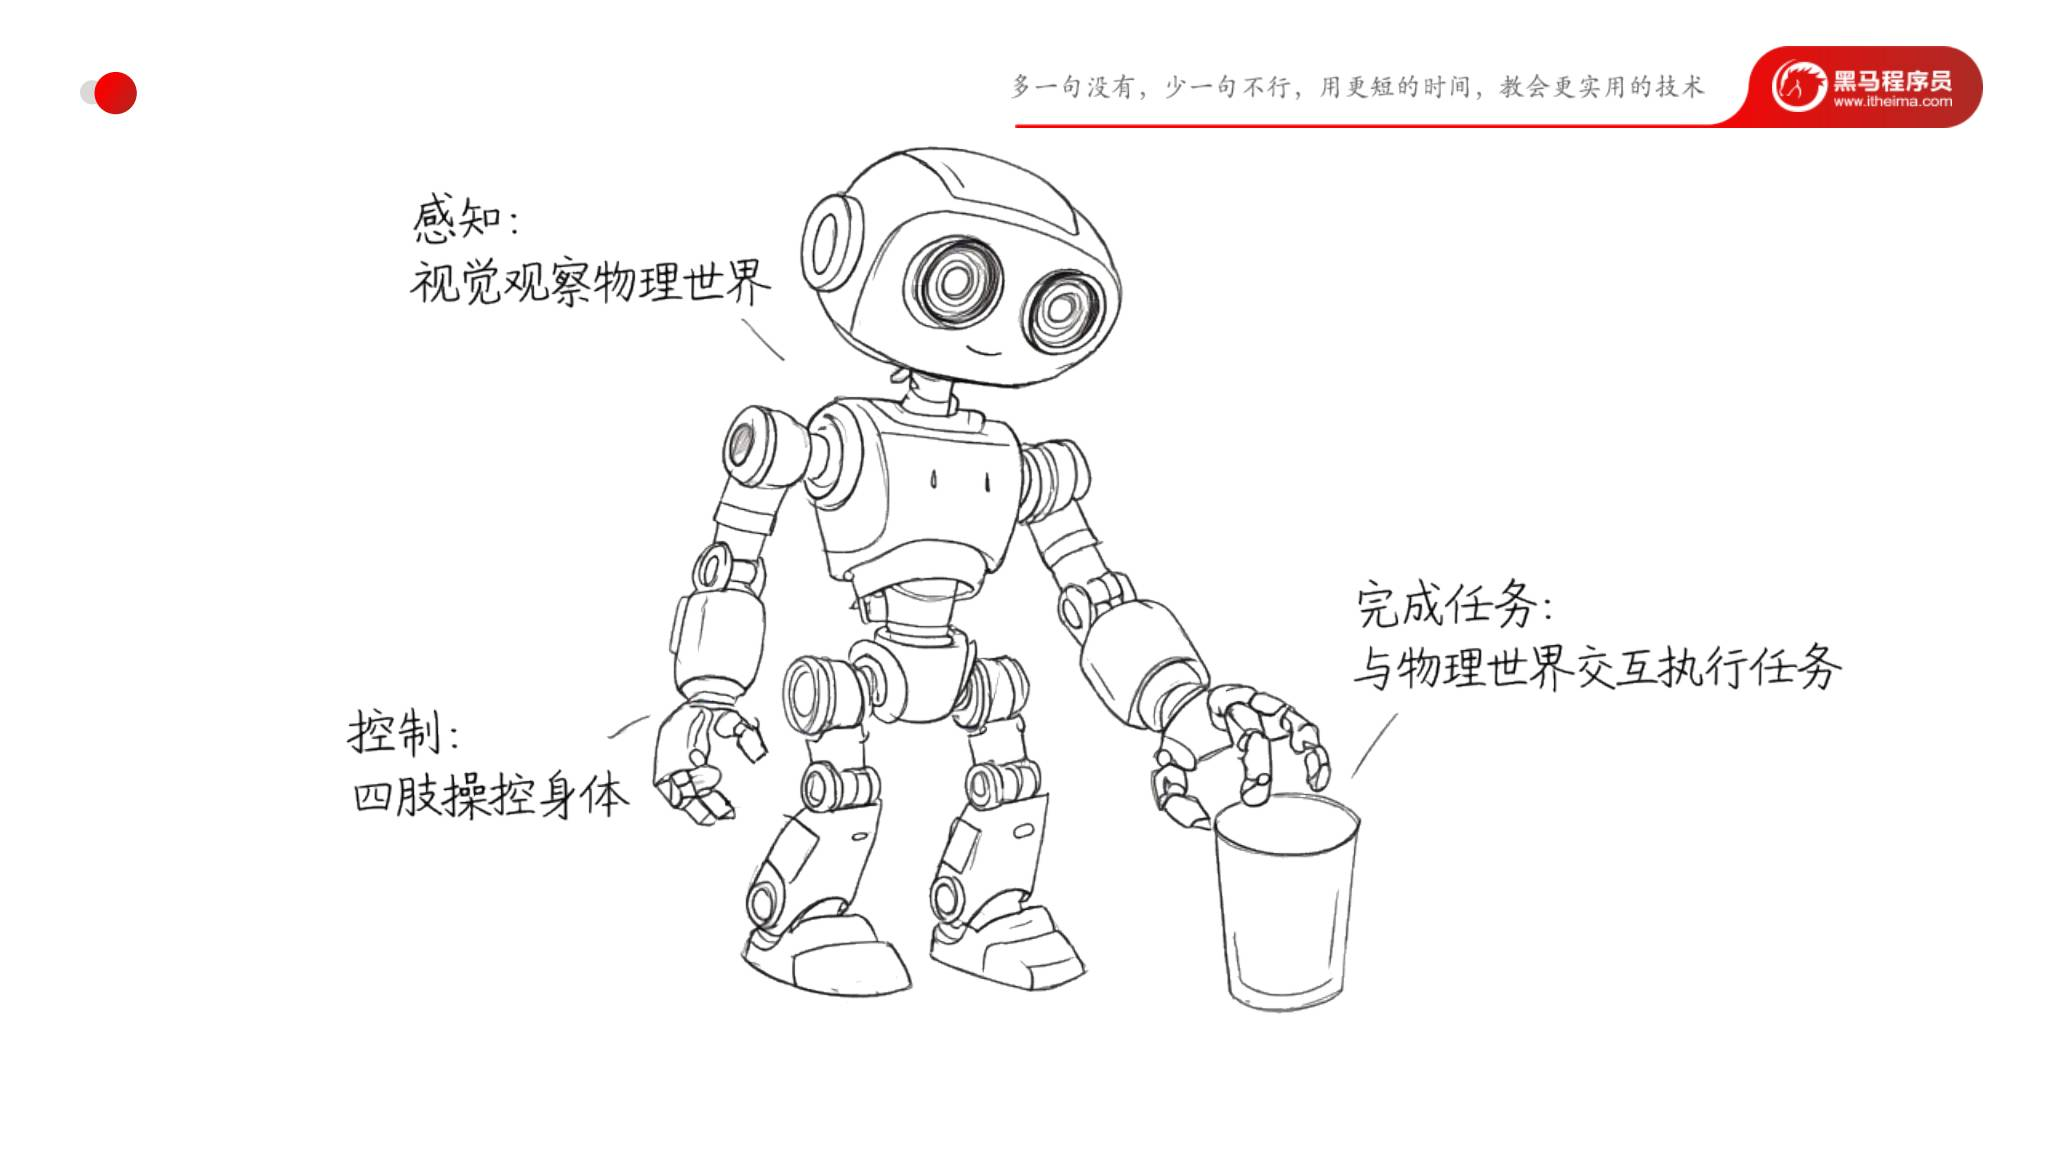

*原课件第 6 页：眼睛对应感知，四肢对应控制，提起物体对应任务执行。*

以拿苹果为例，识别出苹果只是其中一个环节。机器人还要让身体靠近目标，伸手接触并拿住苹果，最终用动作完成任务。这也解释了为什么本课程会同时涉及机器人模型、运动状态和控制逻辑。


## 3. 本课对象：众擎 T800 与仿真环境

课件选择 **众擎 T800** 作为贯穿课程的人形机器人对象。介绍页强调了它作为课程载体的几个特点：国内代表性人形机器人、行走稳定，以及相关资料开放、能够在仿真环境中运行。

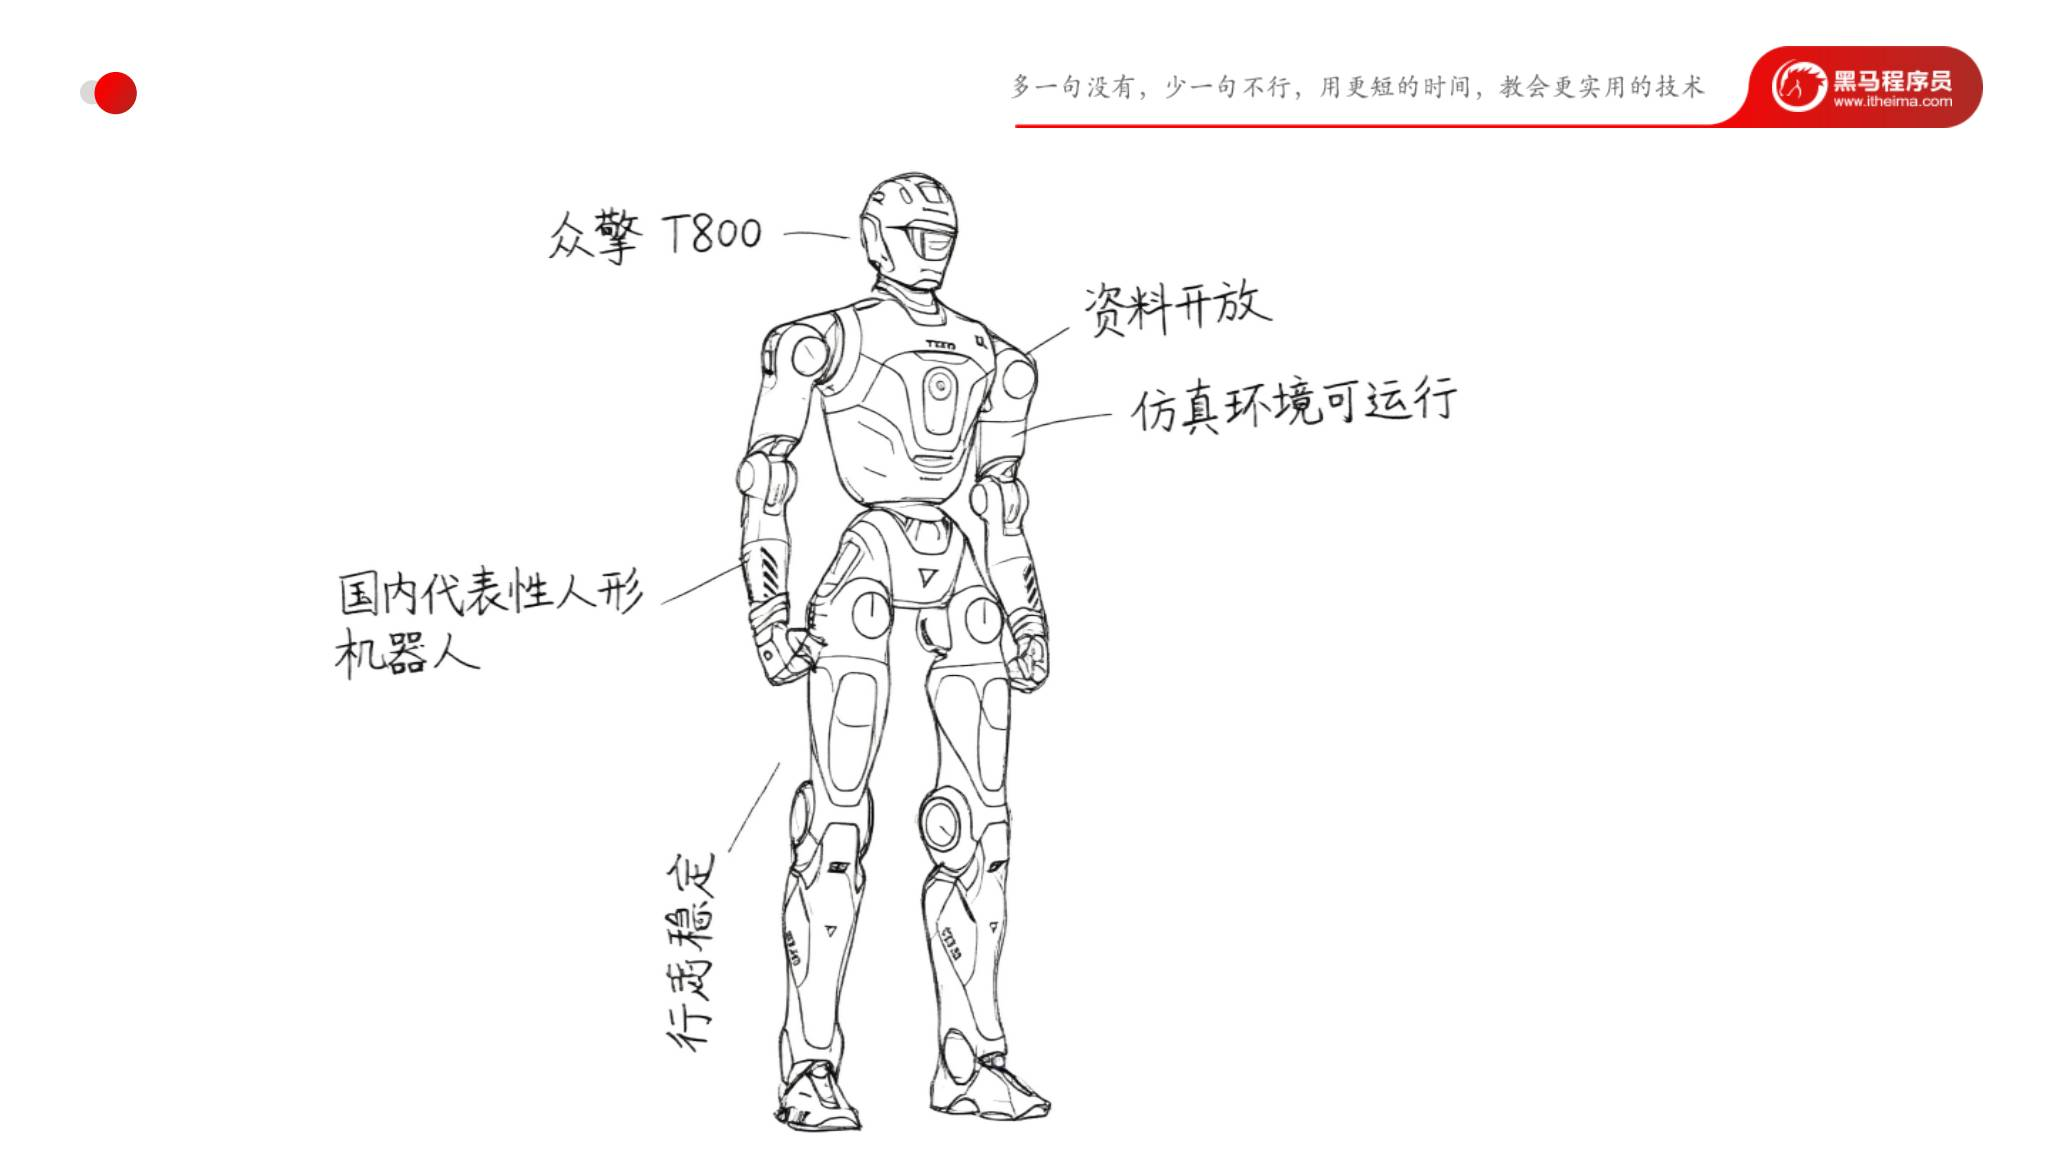

*原课件第 7 页：T800 的课程定位与选用理由。*

对学习者来说，“资料开放”和“仿真环境可运行”意味着可以围绕同一个机器人模型，逐步研究它的结构、状态和控制方式。课程后续将使用 MuJoCo 作为仿真环境，让 T800 模型在计算机中的场景里运动并与物体交互。

这里先区分两个对象：

| 对象 | 本课中的作用 |
|---|---|
| T800 机器人模型 | 描述研究对象的身体结构和相关物理属性 |
| MuJoCo 仿真环境 | 根据模型、状态和控制输入，计算机器人运动以及与场景的物理交互 |

**工程补充：**本课关于 T800 特点的描述属于课程选型介绍，不能据此推导具体硬件版本、关节数量或开放许可范围。仿真中的运动效果也依赖模型与参数，实际硬件表现需要另行验证。


## 4. 学习方式：理清逻辑，再借助 AI 编写代码

第 8 页用“开发机器人是不是要先面对微积分和看不懂的代码”引出学习方法，随后给出“我理清逻辑，AI 写代码”的课程思路，并使用了 **Vibe Coding** 这个说法。

本课希望先降低入门时的理解负担。Python 基础较弱时，也可以先从每个步骤的目的出发，理解机器人如何加载、当前状态如何表示、物理过程怎样推进，再借助 AI 辅助编写相应代码。

学习时应能说清：

- 当前要让机器人完成什么动作。
- 程序需要读取或修改哪些信息。
- 执行后应在仿真中看到什么变化。

这些问题会在后续各节的操作中逐步具体化。本节还没有给出代码或 AI 提示词。

**工程补充：**AI 生成代码之后，仍需对照模型中的名称、接口和参数检查结果，并在仿真中观察行为是否符合目标。理解控制逻辑，才能判断代码是否完成了当前任务。


## 5. 任务预览：行走与物体交互

课件接着展示 T800 与木块交互的连续场景：机器人站在木块旁，调整身体和脚步，俯身接近木块，再拿着木块移动。

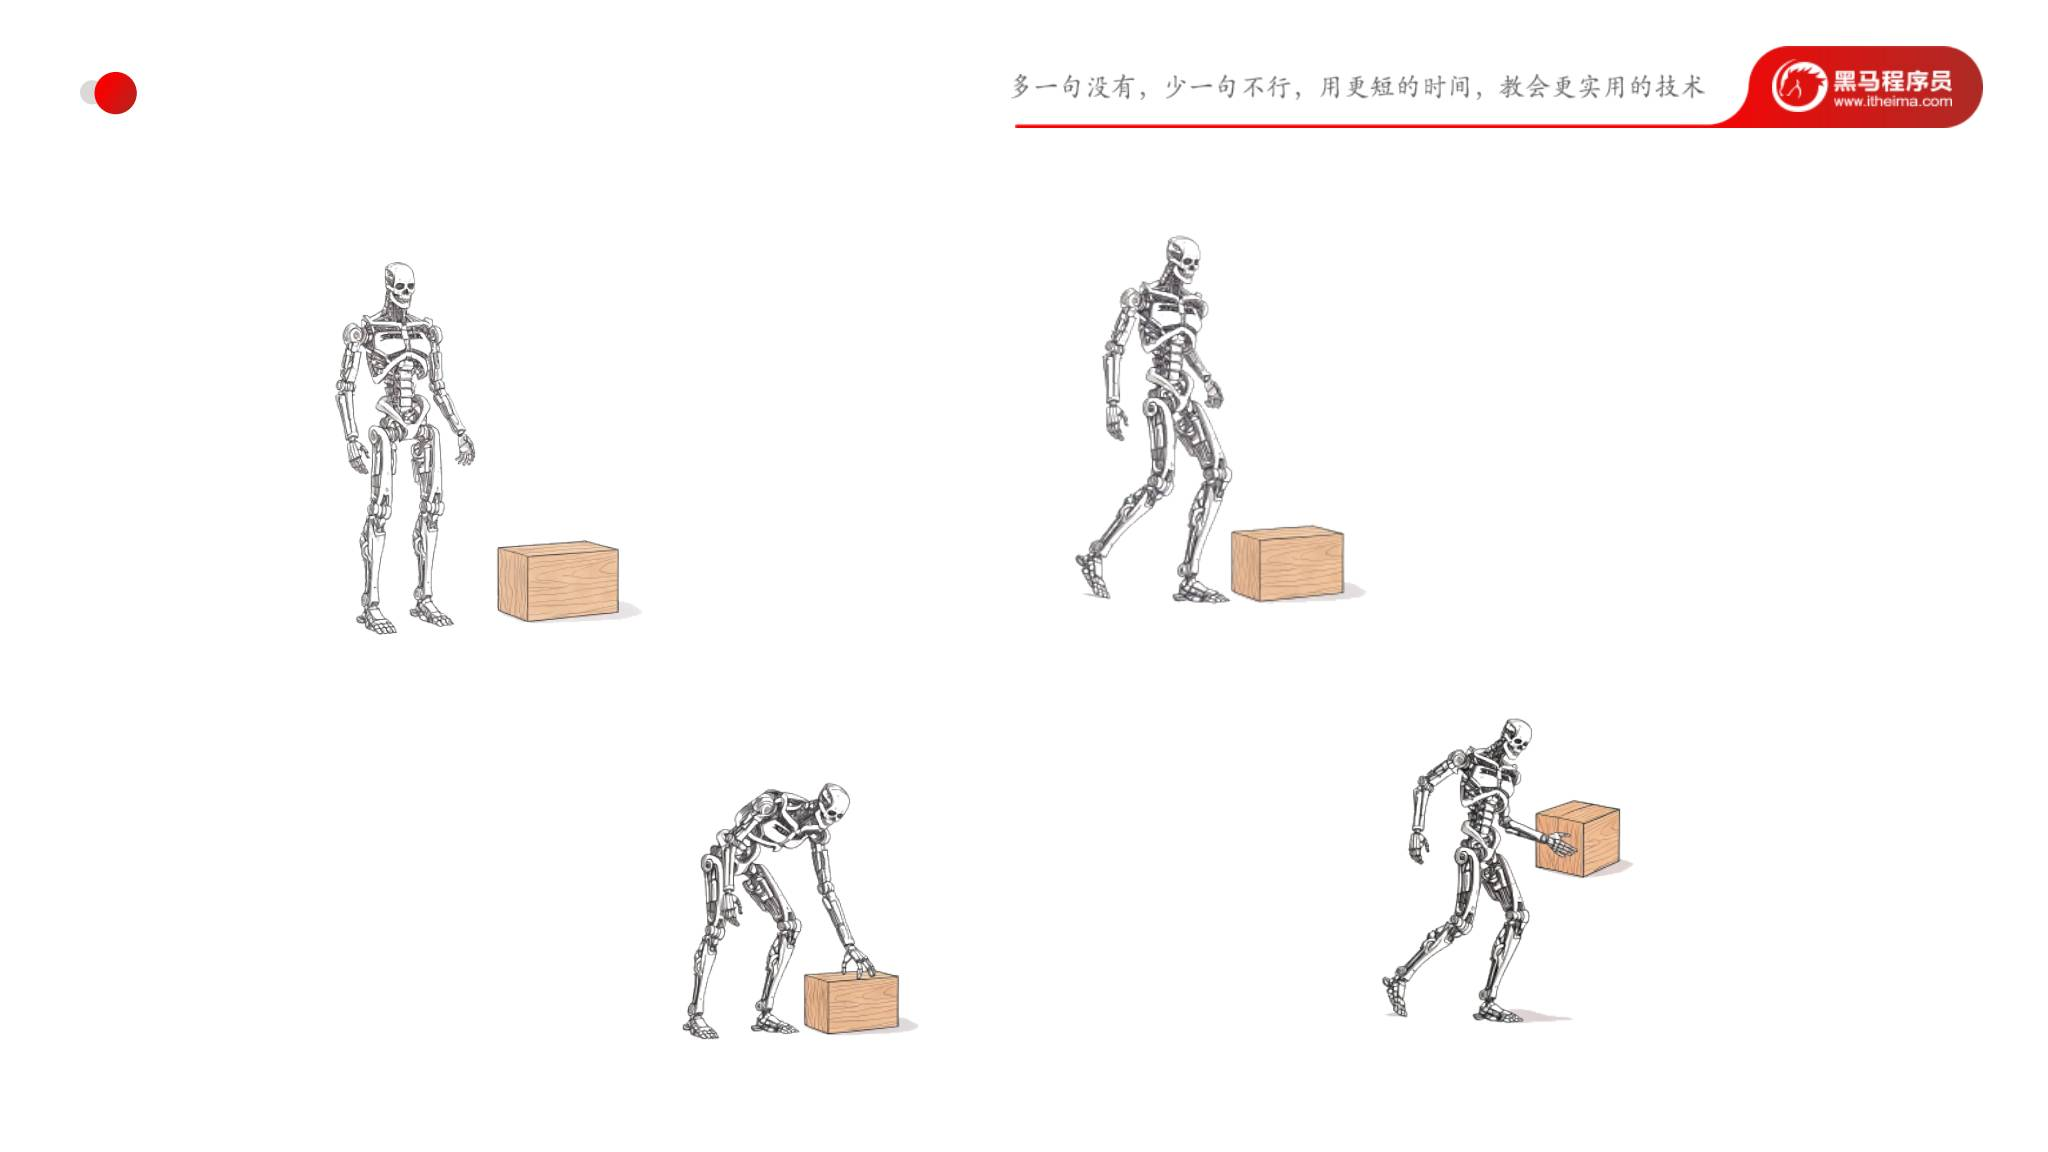

*原课件第 9 页：用连续姿态展示机器人与木块交互的任务方向。*

这组图说明，最终任务需要身体多个部分配合。行走负责移动身体，身体姿态影响手能否接近物体，手与物体接触后还要继续完成后续动作。

本节用这些场景交代学习目标，尚未给出动作轨迹、抓取算法或控制参数。阅读时先把它理解为后续实战的任务预览。


## 6. 机器人仿真的三个基本步骤

课件把机器人仿真的底层逻辑概括为：**模型、状态、物理推发**。下图进一步对应到“加载模型、设定状态、推进仿真”三个操作。

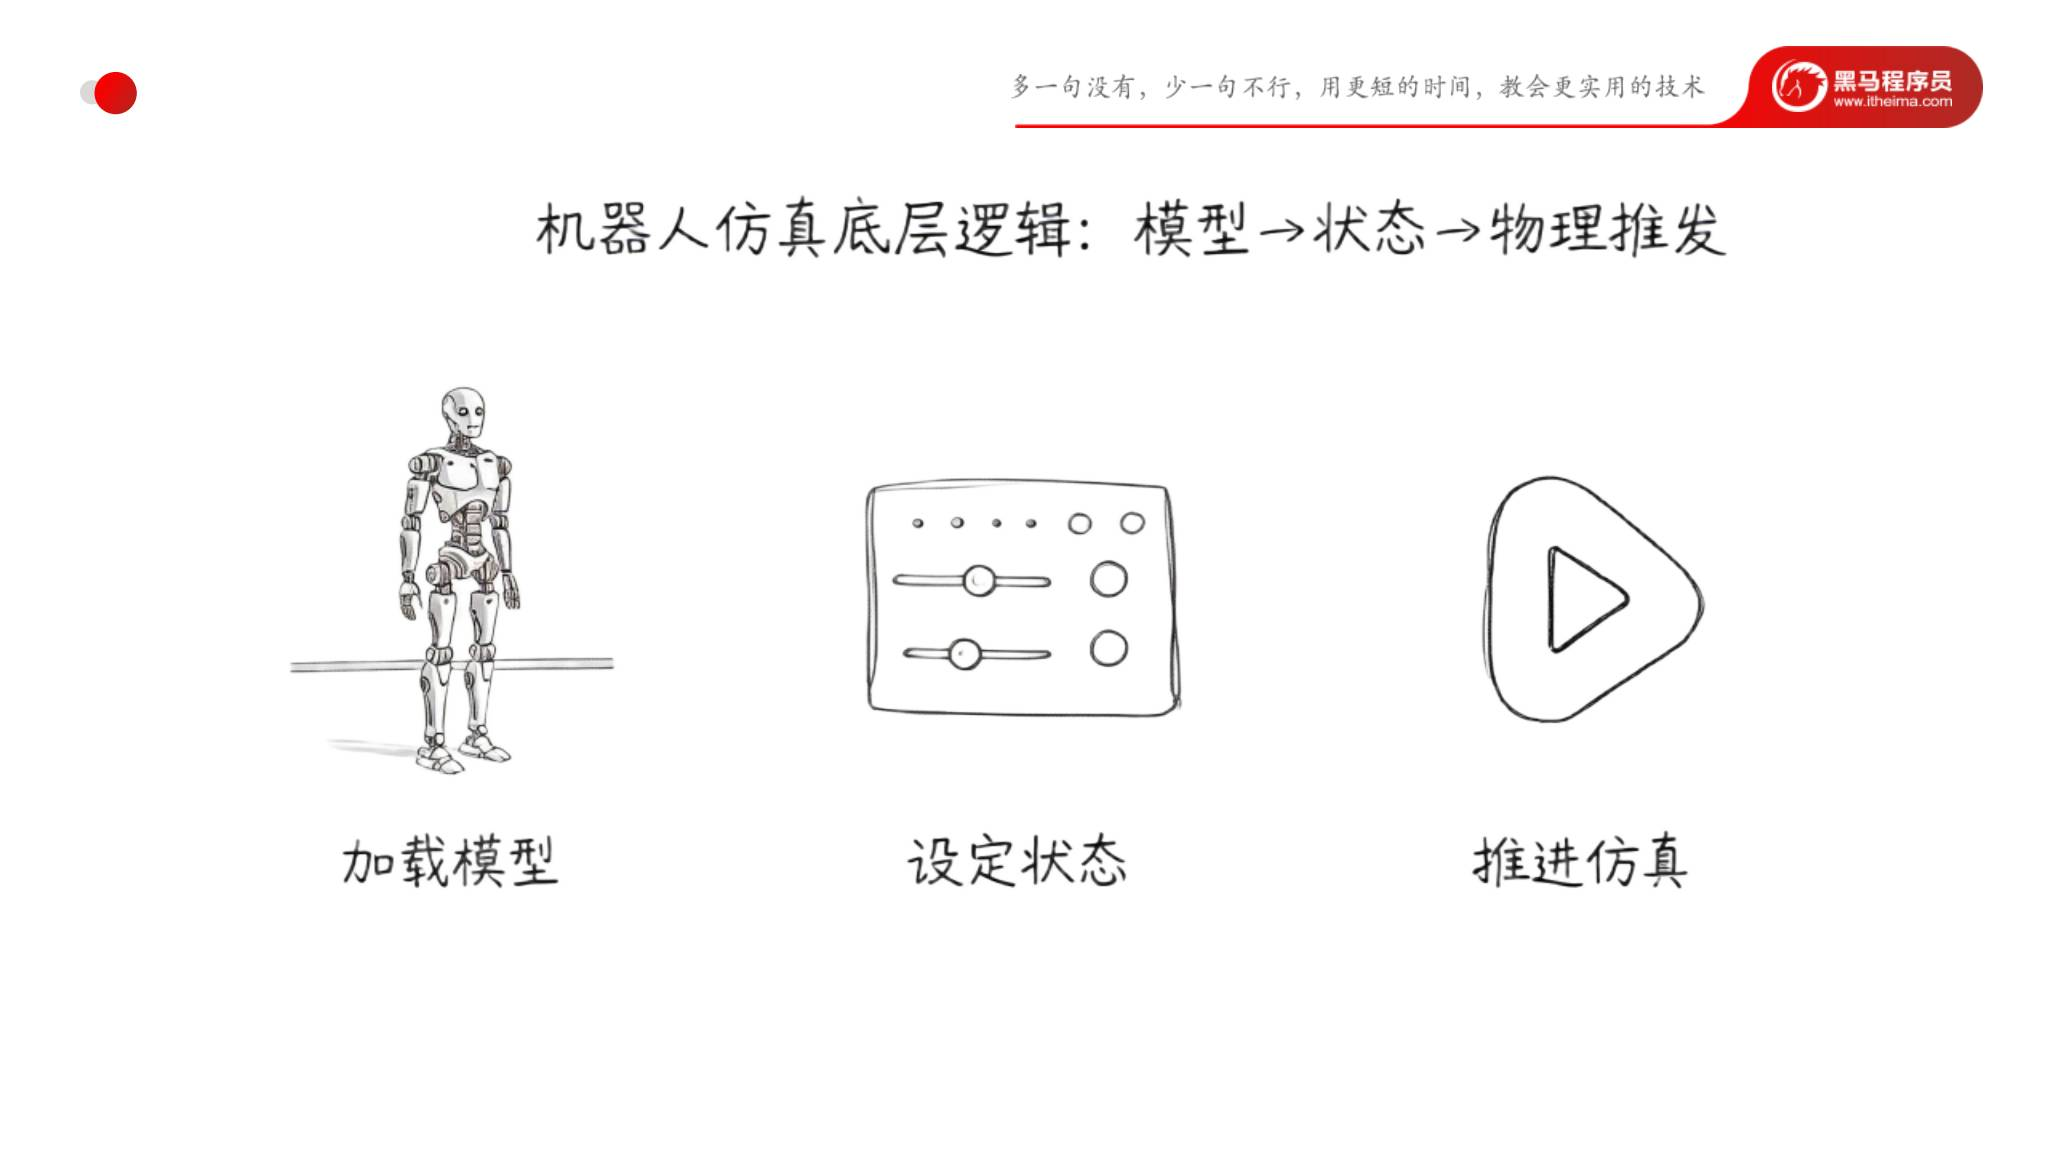

*原课件第 10 页：仿真流程的三个基本步骤。图中“物理推发”结合下方操作理解为推进物理仿真。*

### 6.1 加载模型

首先要让仿真环境知道机器人和场景由什么构成。机器人有哪些身体部件、关节怎样连接，以及各部分有哪些物理属性，都属于模型描述的范围。

模型解决的是“这个仿真对象是什么”。把模型加载进来，才能继续讨论它在某一时刻的位置和运动情况。

### 6.2 设定状态

同一个模型可以有不同的起始姿态和运动情况。例如，机器人可以从不同位置、不同关节姿态开始仿真。课件把位置、速度、力等信息放在仿真数据的说明中。

状态解决的是“这个对象当前处于什么情况”。模型不变，并不意味着每次仿真的状态都相同。

### 6.3 推进仿真

准备好模型和初始状态后，物理引擎开始计算后续变化。每推进一步，当前数据都会随物理计算更新，连续推进后才形成运动过程。

因此，看到机器人模型与看到机器人正确运动，是学习过程中的两个阶段：前者确认模型能够进入仿真场景，后者还需要状态设置和后续控制配合。


## 7. MuJoCo 的基本数据流：XML、Model、Data 与 mj_step()

第 11 页把上一节的三个步骤展开成一张流程图。阅读顺序是：先看左侧的模型和初始数据，再看右侧不断重复的物理计算。

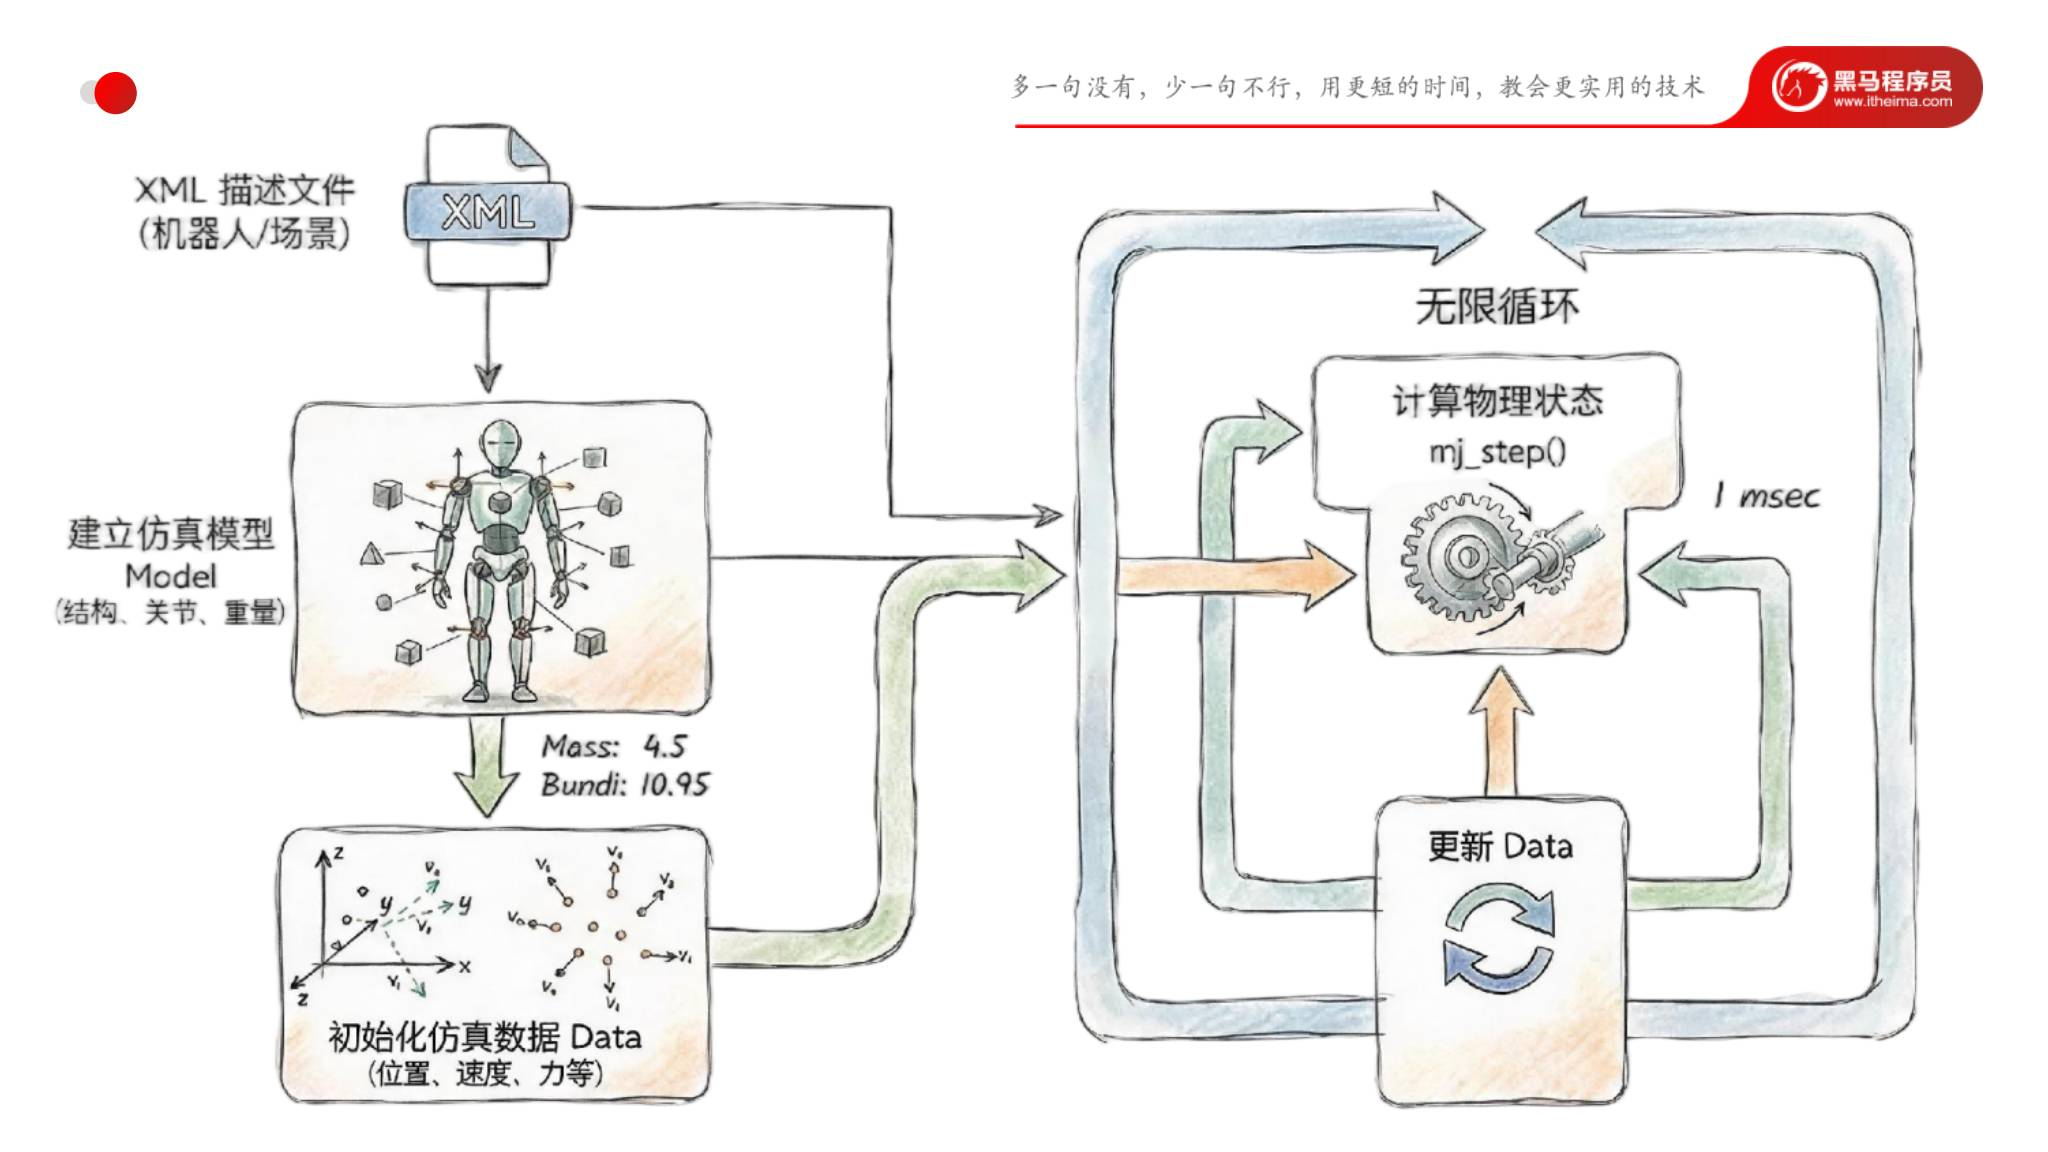

*原课件第 11 页：XML 描述机器人和场景，建立 Model、初始化 Data，然后循环计算物理状态并更新数据。*

### 7.1 XML 描述机器人和场景

课件从 **XML 描述文件** 开始。它是用于组织模型描述的文本格式，这里用来提供机器人与场景的信息。

本节只介绍它在流程中的入口作用，没有展示具体 XML 文件名、配置内容或加载代码。

### 7.2 Model 表示仿真模型

根据描述建立仿真模型 **Model**。图中列出的信息包括结构、关节和重量。

可以把它理解为物理计算需要依据的对象描述：身体由哪些部分构成，这些部分通过什么关节连接，以及相关物理属性是什么。

### 7.3 Data 承载当前仿真数据

建立模型后，初始化仿真数据 **Data**。课件列举了位置、速度、力等信息。

Model 和 Data 的作用不同。Model 描述模型本身，Data 保存当前仿真过程中的数据。仿真推进时，机器人姿态和速度等发生变化，相应数据也随之更新。

| 流程要素 | 课件中的内容 | 理解重点 |
|---|---|---|
| XML | 机器人、场景描述 | 模型信息的来源 |
| Model | 结构、关节、重量 | 物理计算依据的模型属性 |
| Data | 位置、速度、力等 | 当前仿真过程中的数据 |
| `mj_step()` | 计算物理状态 | 推进一个物理计算步并更新相关数据 |
| 循环 | 持续计算和更新 | 把单步状态变化连接成连续运动 |

### 7.4 mj_step() 推进物理计算

图中的 `mj_step()` 位于“计算物理状态”环节。程序反复推进物理计算并更新 Data，下一个计算步再接着使用更新后的数据。

这解释了仿真为什么需要循环：只准备模型和初始状态，不能自动得到完整动作。物理过程要随时间一步步计算，控制程序也要在相应流程中发挥作用。循环的具体写法留到后续课程。

**工程补充：**图中的“更新 Data”表示步进过程中数据发生更新，不要求额外虚构一个名为 `update_data()` 的接口。图上“1 msec”的标注用于示意离散时间步，实际时间步长取决于模型配置，也不能据此认定程序在现实时间中每 1 毫秒完成一次循环。


## 8. 后续课程的三个学习阶段

课件在介绍数据流后，把后续实战归纳为三个阶段。它们从能运行机器人模型开始，逐步发展到运动控制和完整任务。

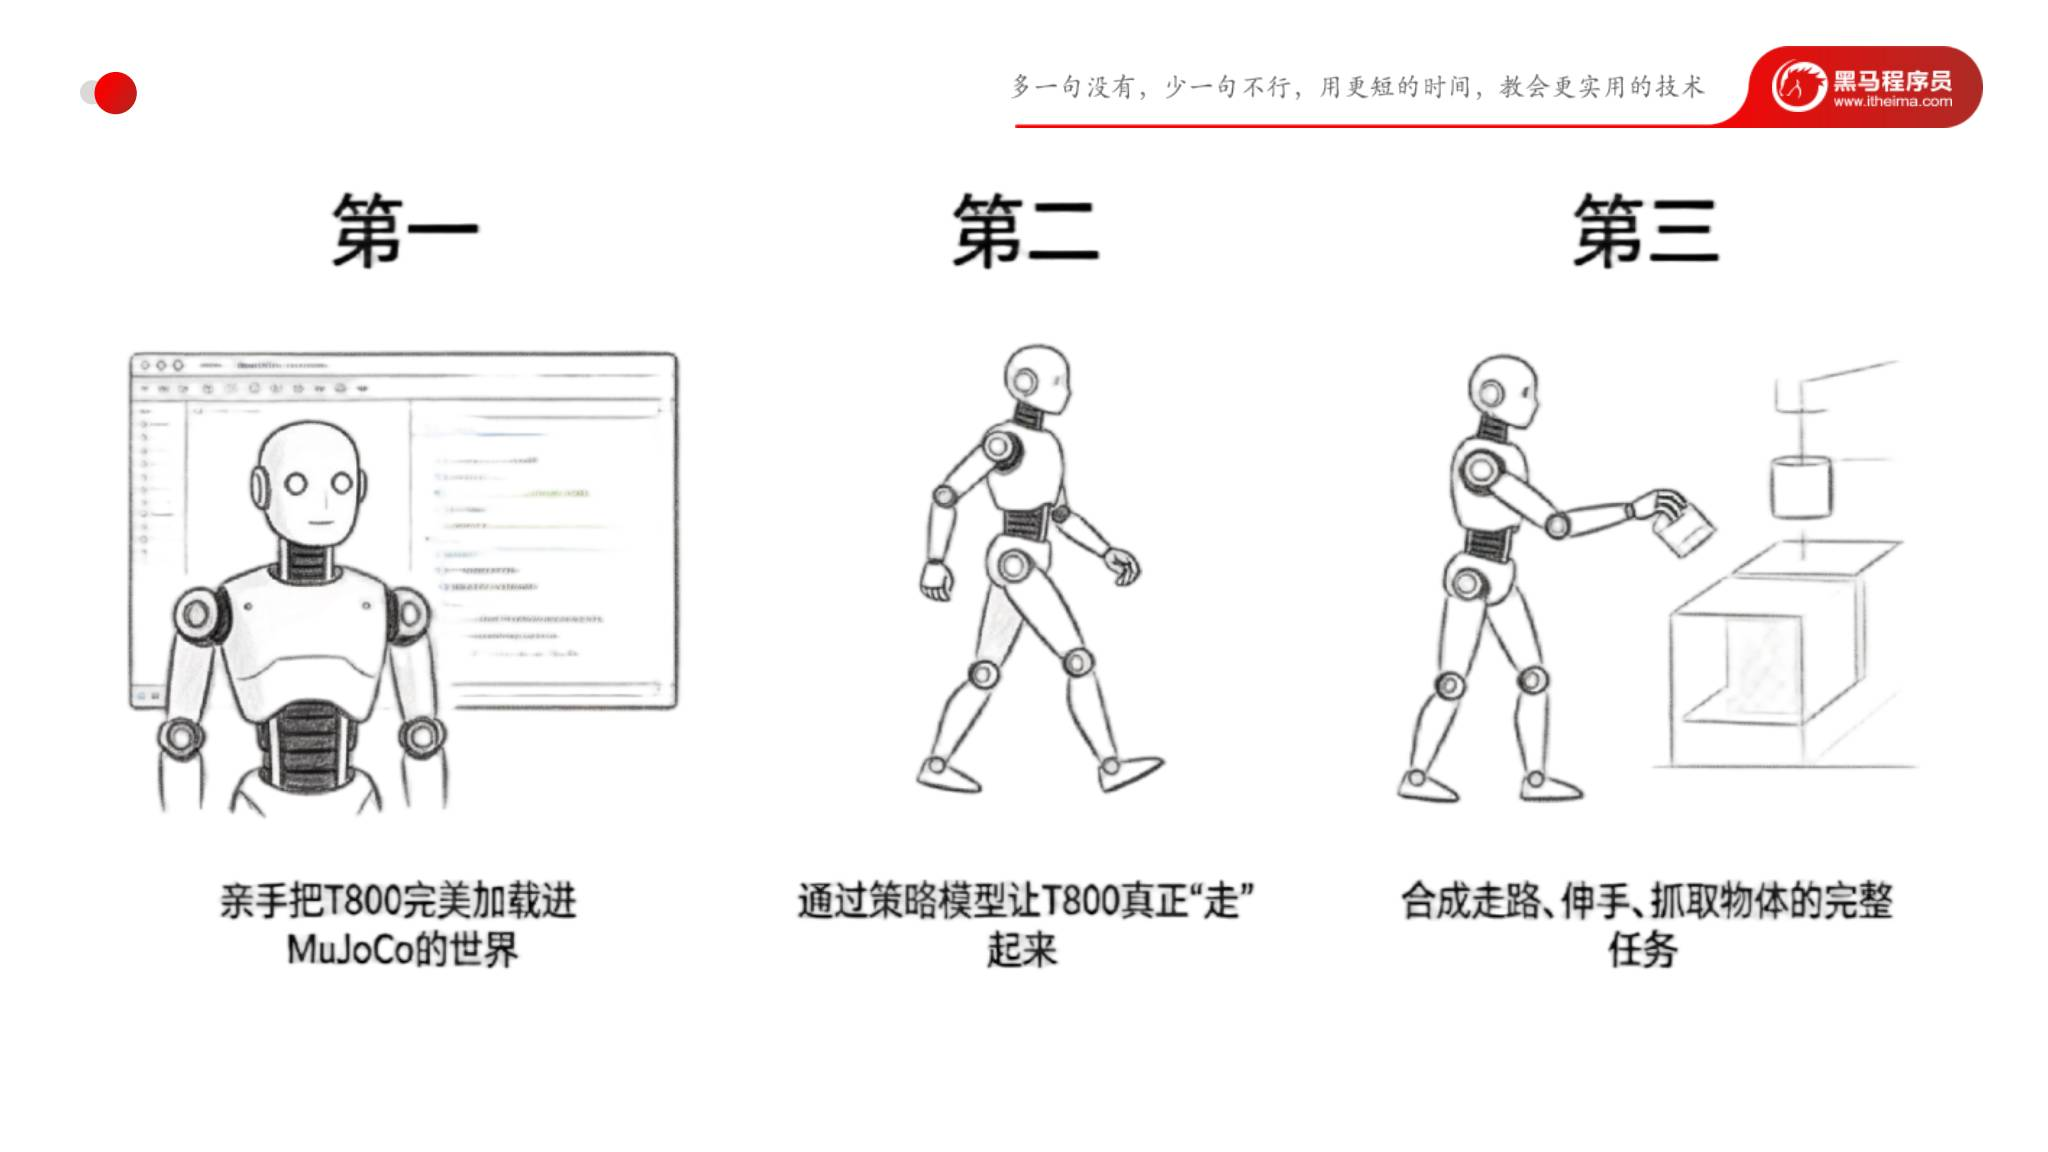

*原课件第 12 页：加载 T800、通过策略模型行走，再组合走路、伸手和抓取任务。*

| 阶段 | 课件中的目标 | 学习时关注的结果 |
|---|---|---|
| 第一阶段 | 把 T800 加载进 MuJoCo 的世界 | 机器人模型能够进入仿真环境 |
| 第二阶段 | 通过策略模型让 T800 走起来 | 策略产生的运动指令能够作用于机器人 |
| 第三阶段 | 合成走路、伸手、抓取物体的完整任务 | 多个动作围绕同一个目标协同执行 |

**策略模型**在这里先理解为参与生成运动指令的模型。本节没有展开模型的训练方式、网络结构或输入输出维度，后续课程会再介绍相应控制过程。

资料中的 21 节课与 21 篇笔记按编号一一对应。下一节课件是《02_mujoco helloworld》，本篇先完成概念导入。


## 9. 本课回顾

课件最后强调：具身智能让 AI 拥有身体，并通过身体在物理世界中执行任务。本课程使用 T800 和 MuJoCo，在仿真环境中学习这一过程。

回看本节，应能把以下概念联系起来：

- **感知、控制与任务执行**说明机器人怎样与环境交互。
- **T800 模型与 MuJoCo**分别提供研究对象和物理仿真环境。
- **模型、状态与推进仿真**构成基本开发流程。
- **XML、Model、Data 与 `mj_step()`**说明模型描述怎样参与连续的物理计算。

本课完成的是对整体流程的认识。安装 MuJoCo、加载具体模型文件、设置关节参数和编写主循环，都需要依照后续课程的实际资料继续展开。
